[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cCoolBoox/IFCD107-alumnado/blob/main/sprints/S12/2_Practica/para_casa/S12_03_nlp_clasico.ipynb)

# S12 · 03 — NLP clásico: sentimiento y temas en las reseñas de TurisData

Sprint 12 · UD 4.8

**Contexto TurisData.** TurisData recibe 1500 reseñas. La dirección no puede leerlas todas: quiere saber *qué opina la gente* (sentimiento) y *de qué habla* (temas).

**Este cuaderno tiene 5 ejercicios y un mini-reto.** Los ejercicios 1, 2, 3 y 4 son los mismos que los del cuaderno «en clase» (allí, del 1 al 4).

**Cómo usar este cuaderno** (tiene dos partes):

- **Parte A · Ejecutar** (aquí abajo): de arriba abajo, cada celda de código lleva encima su título con un símbolo:
    - ⚙️ **Preparación**: se ejecuta sola, pulsa ▶ y sigue.
    - 👀 **Ejemplo**: pulsa ▶, mira el resultado y responde las preguntas 🧠 (no hay que escribir código). Las respuestas están en la Parte B.
    - ✏️ **Ejercicio**: tu turno. Cambia los `...` y pulsa ▶. Si sale **✔**, responde las preguntas 🧠 y sigues. Para comprobar tu código, tienes la solución de referencia ✅ en la Parte B.
- **Parte B · Explicación** (al final): para cada celda, **qué hace**, **qué resultado debe salir** y, en los ejemplos, las **respuestas** a las preguntas 🧠 y, en los ejercicios, la **solución de referencia** ✅ para comprobar tu código. Ábrela cuando quieras entender una celda, comprobar tus respuestas o no te salga. Usa el índice de la izquierda (☰) para saltar.

# Parte A · Ejecutar

### ⚙️ A1 · PREPARACIÓN — se ejecuta sola

Pulsa ▶ y sigue. No hace falta leerla.

In [ ]:
#@title A1 · ▶ Ejecuta esta celda primero (no hace falta leerla)
import os, urllib.request

BASE_URL = "https://raw.githubusercontent.com/cCoolBoox/IFCD107-alumnado/main/datos/"

def dato(nombre):
    """Devuelve la ruta local de un archivo de datos del curso (lo descarga si no está)."""
    for carpeta in ("datos", "../datos", "../../datos", "../../../datos"):
        ruta = os.path.join(carpeta, nombre)
        if os.path.exists(ruta):
            return ruta
    os.makedirs("datos", exist_ok=True)
    ruta = os.path.join("datos", nombre)
    urllib.request.urlretrieve(BASE_URL + nombre, ruta)
    return ruta

import re, unicodedata, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay, f1_score

warnings.filterwarnings("ignore")
SEMILLA = 42
np.random.seed(SEMILLA)
plt.rcParams.update({"figure.figsize": (8, 3.5), "axes.grid": True, "axes.spines.top": False, "axes.spines.right": False})
print("Listo ✔")

Listo ✔


### 👀 A2 · EJEMPLO — Cargar las reseñas

Pulsa ▶ y mira lo que sale. **No hay que escribir nada.**

🧠 **Autoejercicio:** mira el resultado y responde (respuestas en la Parte B, A2).

1. ¿Cuántas reseñas y columnas hay?
2. ¿Qué información tiene cada reseña?
3. ¿Por qué hay que tener cuidado con estos datos?

In [ ]:
resenas = pd.read_csv(dato("resenas.csv"))
print(resenas.shape)
resenas.head()

(1500, 5)


,id_resena,texto,nota,sentimiento,temas
0,1,Escapada de fin de semana. La música del bar n...,3,neutro,"ruido,ubicacion"
1,2,Pasamos una semana aquí. Cobran extras por tod...,1,negativo,precio
2,3,"En general, Buenos productos locales en el des...",4,positivo,"desayuno,precio,ruido"
3,4,El desayuno buffet es variado y delicioso.,4,positivo,desayuno
4,5,Escapada de fin de semana. Se duerme de maravi...,4,positivo,"personal,ruido,ubicacion"


### 👀 A3 · EJEMPLO — Distribución del sentimiento y reseñas de ejemplo

Pulsa ▶ y mira lo que sale. **No hay que escribir nada.**

🧠 **Autoejercicio:** mira el resultado y responde (respuestas en la Parte B, A3).

1. ¿Qué sentimiento es el más frecuente y qué proporción tiene?
2. ¿Cuántas palabras tiene una reseña de media?
3. ¿Qué proporción acertaría un modelo que dijera siempre «positivo»?

In [ ]:
print(resenas["sentimiento"].value_counts(normalize=True).round(3).to_string())
resenas["longitud"] = resenas["texto"].str.split().str.len()
print("Palabras por reseña (media):", round(resenas["longitud"].mean(), 1))
for t in resenas.sample(3, random_state=SEMILLA)["texto"]:
    print("-", t)

sentimiento
positivo    0.469
negativo    0.319
neutro      0.212
Palabras por reseña (media): 14.0
- Fuimos por trabajo. Se oye todo de la habitación de al lado. Está muy lejos del centro. Tardaron una hora en resolver un problema simple.
- Pasamos una semana aquí. Muy buena relación calidad precio. La limpieza de la habitación era impecable. Está muy bien situado, cerca de todo.
- Viajamos en familia. Todo estaba muy limpio!


### ✏️ A4 · EJERCICIO 1 de 5 — Limpiar un texto

**Tu turno:** Completa `limpiar(texto)`: pasa a minúsculas, cambia todo lo que no sean letras (incluidas tildes y ñ) o espacios por un espacio, y colapsa espacios repetidos. Debe cumplir `limpiar("¡Qué BUENO!... Sí") == "qué bueno sí"`.

**Debe salir:** `'qué bueno sí' · 'precio ok'` y ✔ Ejercicio 1 correcto

Cambia los `...` y pulsa ▶.

🧠 **Autoejercicio:** cuando salga ✔, responde (respuestas en la Parte B, A4).

1. ¿Qué devuelve `limpiar("Precio 3€, ok")`?
2. ¿Por qué la expresión regular incluye `áéíóúüñ`?
3. ¿Para qué sirve `" ".join(texto.split())`?

✅ ¿Dudas de tu código? Compáralo con la solución de referencia en la Parte B, A4, **después de intentarlo**.

In [ ]:
def limpiar(texto):
    # pista: texto.lower(), re.sub(r"[^a-záéíóúüñ\s]", " ", ...) y luego " ".join(texto.split())
    texto = texto.lower()
    texto = re.sub(r"[^a-záéíóúüñ\s]", " ", texto)
    return " ".join(texto.split())

assert limpiar("¡Qué BUENO!...  Sí") == "qué bueno sí", "Revisa limpiar: minúsculas, signos fuera y espacios únicos."
assert limpiar("Precio 3€, ok") == "precio ok", "Los números y símbolos también se eliminan."
print(repr(limpiar("¡Qué BUENO!...  Sí")), "·", repr(limpiar("Precio 3€, ok")))
print("✔ Ejercicio 1 correcto")

'qué bueno sí' · 'precio ok'
✔ Ejercicio 1 correcto


### 👀 A5 · EJEMPLO — Quitar las palabras vacías y tokenizar

Pulsa ▶ y mira lo que sale. **No hay que escribir nada.**

🧠 **Autoejercicio:** mira el resultado y responde (respuestas en la Parte B, A5).

1. ¿Qué tokens salen de la frase de ejemplo?
2. ¿Por qué no se quita «no» de las palabras vacías?
3. ¿Qué es un token?

In [ ]:
PALABRAS_VACIAS = {"a", "al", "con", "de", "del", "el", "en", "es", "esta", "estaba", "era", "fue", "la", "las", "lo", "los",
                   "me", "mi", "muy", "nos", "para", "por", "que", "se", "su", "un", "una", "y", "o", "u", "e"}

def tokenizar(texto, quitar_vacias=True):
    tokens = limpiar(texto).split()
    return [t for t in tokens if not (quitar_vacias and t in PALABRAS_VACIAS)]

print(tokenizar("La limpieza de la habitación era impecable!"))
resenas["limpio"] = resenas["texto"].apply(limpiar)

['limpieza', 'habitación', 'impecable']


sentimiento
positivo    46.9
neutro      21.2
negativo    31.9
Name: proportion, dtype: float64
Suma: 100.0


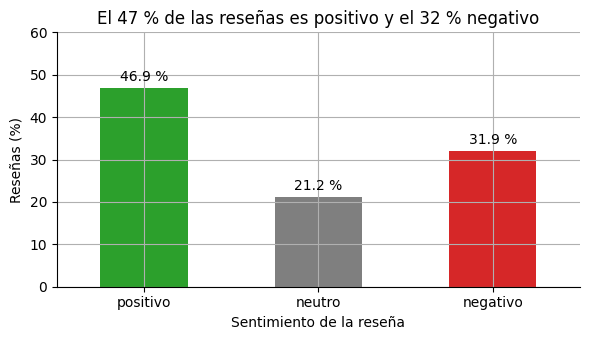

In [ ]:
porcentajes = (resenas["sentimiento"].value_counts(normalize=True) * 100).round(1)
porcentajes = porcentajes.reindex(["positivo", "neutro", "negativo"])
print(porcentajes)
print("Suma:", porcentajes.sum())

fig, ax = plt.subplots(figsize=(6, 3.5))
porcentajes.plot.bar(ax=ax, color=["tab:green", "tab:gray", "tab:red"], rot=0)
ax.bar_label(ax.containers[0], fmt="%.1f %%", padding=3)
ax.set_ylim(0, 60)
ax.set_title(f"El {porcentajes['positivo']:.0f} % de las reseñas es positivo y el {porcentajes['negativo']:.0f} % negativo")
ax.set_xlabel("Sentimiento de la reseña")
ax.set_ylabel("Reseñas (%)")
plt.tight_layout()
plt.savefig("grafico_resenas.png", dpi=150)
plt.show()

### ✏️ A6 · EJERCICIO 2 de 5 — Las 5 palabras más frecuentes

**Tu turno:** ¿Cuáles son las 5 palabras (tokens, ya sin palabras vacías) más frecuentes de todo el corpus? Guarda en `top5` una lista de 5 tuplas `(palabra, veces)`. Pista: `collections.Counter` y `.most_common(5)`.

**Debe salir:** `[('semana', 504), ('desayuno', 391), ('todo', 382), ('habitación', 284), ('escapada', 256)]` y ✔ Ejercicio 2 correcto

Cambia los `...` y pulsa ▶.

🧠 **Autoejercicio:** cuando salga ✔, responde (respuestas en la Parte B, A6).

1. ¿Cuál es la palabra más frecuente y cuántas veces aparece?
2. ¿Por qué «semana», «todo» y «escapada» salen tan arriba?
3. ¿Qué devuelve `most_common(5)`?

✅ ¿Dudas de tu código? Compáralo con la solución de referencia en la Parte B, A6, **después de intentarlo**.

In [ ]:
from collections import Counter
# pista: Counter sobre todos los tokens de resenas["texto"]
contador = Counter(t for texto in resenas["texto"] for t in tokenizar(texto))
top5 = contador.most_common(5)

assert len(top5) == 5 and all(len(x) == 2 for x in top5), "top5 debe ser una lista de 5 pares (palabra, veces)."
assert top5[0][1] >= top5[4][1], "Ordénalas de mayor a menor frecuencia."
assert all(p not in PALABRAS_VACIAS for p, _ in top5), "Quita las palabras vacías con tokenizar()."
print(top5)
print("✔ Ejercicio 2 correcto")

[('semana', 504), ('desayuno', 391), ('todo', 382), ('habitación', 284), ('escapada', 256)]
✔ Ejercicio 2 correcto


### 👀 A7 · EJEMPLO — Bolsa de palabras y TF-IDF con tres frases

Pulsa ▶ y mira lo que sale. **No hay que escribir nada.**

🧠 **Autoejercicio:** mira el resultado y responde (respuestas en la Parte B, A7).

1. ¿Qué contiene cada columna de la bolsa de palabras?
2. ¿Qué peso tiene «sucia» en TF-IDF y por qué es mayor que el de «desayuno»?
3. ¿Qué se pierde en la bolsa de palabras?

In [ ]:
ejemplo = ["el desayuno era escaso", "el desayuno merece la pena", "la habitación estaba sucia"]
bow = CountVectorizer()
M = bow.fit_transform(ejemplo)
print(pd.DataFrame(M.toarray(), columns=bow.get_feature_names_out(), index=["r1", "r2", "r3"]))
tf = TfidfVectorizer()
M2 = tf.fit_transform(ejemplo)
print(pd.DataFrame(M2.toarray().round(2), columns=tf.get_feature_names_out(), index=["r1", "r2", "r3"]))

    desayuno  el  era  escaso  estaba  habitación  la  merece  pena  sucia
r1         1   1    1       1       0           0   0       0     0      0
r2         1   1    0       0       0           0   1       1     1      0
r3         0   0    0       0       1           1   1       0     0      1
    desayuno    el   era  escaso  estaba  habitación    la  merece  pena  \
r1      0.43  0.43  0.56    0.56    0.00        0.00  0.00    0.00  0.00   
r2      0.39  0.39  0.00    0.00    0.00        0.00  0.39    0.52  0.52   
r3      0.00  0.00  0.00    0.00    0.53        0.53  0.40    0.00  0.00   

    sucia  
r1   0.00  
r2   0.00  
r3   0.53  


### 👀 A8 · EJEMPLO — Partir en entrenamiento y prueba

Pulsa ▶ y mira lo que sale. **No hay que escribir nada.**

🧠 **Autoejercicio:** mira el resultado y responde (respuestas en la Parte B, A8).

1. ¿Cuántas reseñas hay para entrenar y para probar?
2. ¿Para qué sirve `stratify`?
3. ¿Por qué se usa un *pipeline*?

In [ ]:
from sklearn.pipeline import make_pipeline

X_ent, X_test, y_ent, y_test = train_test_split(resenas["texto"], resenas["sentimiento"], test_size=0.25,
                                                stratify=resenas["sentimiento"], random_state=SEMILLA)
print(len(X_ent), "para entrenar,", len(X_test), "para probar")

1125 para entrenar, 375 para probar


### ✏️ A9 · EJERCICIO 3 de 5 — Regresión logística frente a Naive Bayes

**Tu turno:** Crea y entrena dos modelos y guarda su exactitud en prueba: - `modelo_lr`: `TfidfVectorizer(preprocessor=limpiar)` + `LogisticRegression(max_iter=1000)` → `acc_lr` - `modelo_nb`: `CountVectorizer(preprocessor=limpiar)` + `MultinomialNB()` → `acc_nb` Usa `make_pipeline(vectorizador, clasificador)` y `.fit(X_ent, y_ent)`.

**Debe salir:** `Regresión logística + TF-IDF : 0.992`, `Naive Bayes + bolsa de palabras: 0.989`, la referencia de la clase mayoritaria (0.469) y ✔ Ejercicio 3 correcto

Cambia los `...` y pulsa ▶.

🧠 **Autoejercicio:** cuando salga ✔, responde (respuestas en la Parte B, A9).

1. ¿Qué exactitud logran los dos modelos y cuál es la referencia?
2. ¿Qué hace `preprocessor=limpiar` en el vectorizador?
3. ¿Por qué no hay que fiarse tanto de un 99 %?

✅ ¿Dudas de tu código? Compáralo con la solución de referencia en la Parte B, A9, **después de intentarlo**.

In [ ]:
# pista: make_pipeline(TfidfVectorizer(preprocessor=limpiar), LogisticRegression(max_iter=1000)) y análogo para NB
modelo_lr = make_pipeline(TfidfVectorizer(preprocessor=limpiar), LogisticRegression(max_iter=1000)).fit(X_ent, y_ent)
acc_lr = accuracy_score(y_test, modelo_lr.predict(X_test))
modelo_nb = make_pipeline(CountVectorizer(preprocessor=limpiar), MultinomialNB()).fit(X_ent, y_ent)
acc_nb = accuracy_score(y_test, modelo_nb.predict(X_test))

print(f"Regresión logística + TF-IDF : {acc_lr:.3f}")
print(f"Naive Bayes + bolsa de palabras: {acc_nb:.3f}")
assert acc_lr > 0.7 and acc_nb > 0.7, "Las dos exactitudes deberían superar 0.7. Revisa el pipeline y que uses X_ent/y_ent para entrenar."
baseline = y_test.value_counts(normalize=True).max()
print(f"(Un clasificador que siempre dice la clase mayoritaria acertaría {baseline:.3f})")
print("✔ Ejercicio 3 correcto")

Regresión logística + TF-IDF : 0.992
Naive Bayes + bolsa de palabras: 0.989
(Un clasificador que siempre dice la clase mayoritaria acertaría 0.469)
✔ Ejercicio 3 correcto


### Cómo evitamos la fuga de datos


Separamos las 1.500 reseñas en 1.125 para entrenamiento y 375 para prueba antes de vectorizar. Al ajustar el pipeline de regresión logística, TF-IDF aprende el vocabulario y el peso de las palabras solo con el conjunto de entrenamiento. En prueba, el pipeline transforma las 375 reseñas con ese mismo vectorizador, sin volver a ajustarlo. Naive Bayes sigue el mismo orden con su bolsa de palabras. Así, reservamos la prueba para medir el rendimiento.


### 👀 A10 · EJEMPLO — Informe de clasificación y matriz de confusión

Pulsa ▶ y mira lo que sale. **No hay que escribir nada.**

🧠 **Autoejercicio:** mira el resultado y responde (respuestas en la Parte B, A10).

1. ¿Qué clase tiene el *recall* más bajo y cuánto vale?
2. ¿Qué indican los números fuera de la diagonal de la matriz?
3. ¿Cuántas reseñas de prueba hay de cada sentimiento?

              precision    recall  f1-score   support

    negativo       0.98      1.00      0.99       120
      neutro       1.00      0.96      0.98        79
    positivo       1.00      1.00      1.00       176

    accuracy                           0.99       375
   macro avg       0.99      0.99      0.99       375
weighted avg       0.99      0.99      0.99       375



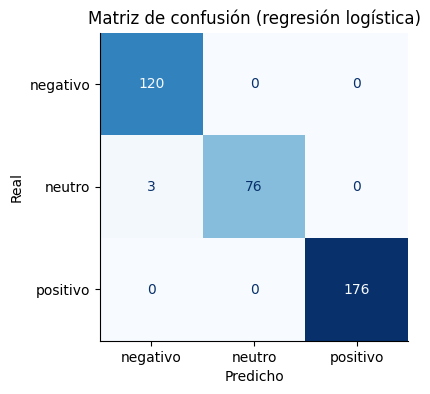

In [ ]:
print(classification_report(y_test, modelo_lr.predict(X_test)))
fig, ax = plt.subplots(figsize=(4.5, 4))
ConfusionMatrixDisplay.from_predictions(y_test, modelo_lr.predict(X_test), ax=ax, cmap="Blues", colorbar=False)
ax.set_title("Matriz de confusión (regresión logística)"); ax.set_xlabel("Predicho"); ax.set_ylabel("Real"); ax.grid(False)
plt.show()

### 👀 A11 · EJEMPLO — ¿Qué palabras pesan en el modelo?

Pulsa ▶ y mira lo que sale. **No hay que escribir nada.**

🧠 **Autoejercicio:** mira el resultado y responde (respuestas en la Parte B, A11).

1. ¿Qué palabras empujan más a «negativo»?
2. ¿Qué ventaja tiene poder ver los pesos?
3. ¿Qué pesos te parecen sospechosos?

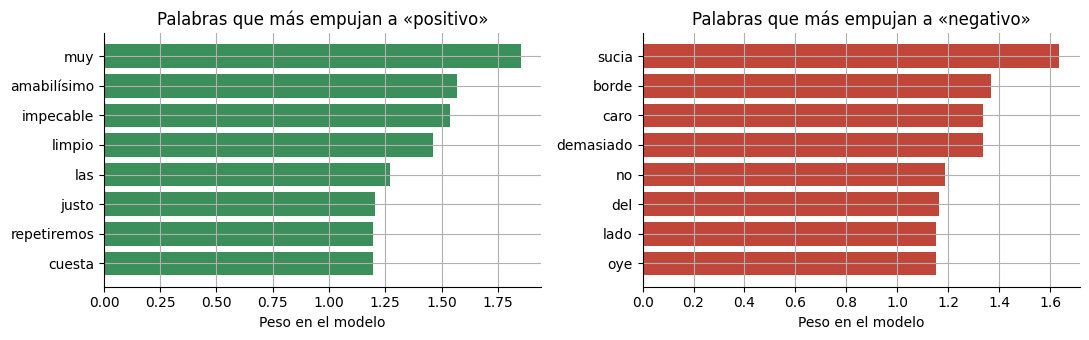

In [ ]:
vec, clf = modelo_lr.named_steps["tfidfvectorizer"], modelo_lr.named_steps["logisticregression"]
vocab = np.array(vec.get_feature_names_out())
fig, ejes = plt.subplots(1, 2, figsize=(11, 3.5))
for ax, clase, color in zip(ejes, ["positivo", "negativo"], ["#3b8f5a", "#c0463a"]):
    i = list(clf.classes_).index(clase)
    top = np.argsort(clf.coef_[i])[-8:]
    ax.barh(vocab[top], clf.coef_[i][top], color=color)
    ax.set_title(f"Palabras que más empujan a «{clase}»"); ax.set_xlabel("Peso en el modelo")
plt.tight_layout(); plt.show()

### 👀 A12 · EJEMPLO — Probar frases nuevas con negaciones

Pulsa ▶ y mira lo que sale. **No hay que escribir nada.**

🧠 **Autoejercicio:** mira el resultado y responde (respuestas en la Parte B, A12).

1. ¿Qué predice el modelo para «La limpieza no es impecable»?
2. ¿Y para «El personal no fue borde»?
3. ¿Por qué falla con las negaciones?

In [ ]:
pruebas = ["La limpieza es impecable", "La limpieza no es impecable", "El personal fue borde", "El personal no fue borde",
           "Vistas increíbles pero un ruido constante"]
for f, p in zip(pruebas, modelo_lr.predict(pruebas)):
    print(f"{p:9s} ← {f}")

positivo  ← La limpieza es impecable
positivo  ← La limpieza no es impecable
negativo  ← El personal fue borde
negativo  ← El personal no fue borde
negativo  ← Vistas increíbles pero un ruido constante


### ✏️  A13 · EJERCICIO 4 de 5 — ¿Falla con las negaciones?

**Tu turno:** Observa los resultados y escribe en `falla_negacion` (True/False) si el modelo trata igual las frases "con negación" que las "sin negación" (es decir, ¿se equivoca con "no es impecable"?). Después, en `bigrama_util`, escribe (texto) por qué usar **bigramas** (`ngram_range=(1, 2)`) podría ayudar en una frase. Pista: los bigramas conservan pares como "no es".

**Debe salir:** `¿El modelo falla con la negación? True` · `Tu explicación: Un bigrama junta dos palabras seguidas (p. ej. «no es»), así conserva parte del orden y de la negación.` y ✔ Ejercicio 4 correcto

Cambia los `...` y pulsa ▶.

🧠 **Autoejercicio:** cuando salga ✔, responde (respuestas en la Parte B, A13).

1. ¿Cuánto vale `falla_negacion` y qué significa?
2. ¿Qué es un bigrama?
3. ¿Por qué ayudan los bigramas con las negaciones?

✅ ¿Dudas de tu código? Compáralo con la solución de referencia en la Parte B, A13, **después de intentarlo**.

In [ ]:
# pista: compara la predicción de la 1.ª y 2.ª frase; explica que un bigrama como «no fue» mantiene la negación junto a la palabra
falla_negacion = modelo_lr.predict([pruebas[1]])[0] == "positivo"
bigrama_util = "Un bigrama junta dos palabras seguidas (p. ej. «no es»), así conserva parte del orden y de la negación."

assert isinstance(falla_negacion, (bool, np.bool_)), "falla_negacion debe ser True o False."
assert len(bigrama_util) > 30, "Escribe una explicación de al menos una frase en bigrama_util."
print("¿El modelo falla con la negación?", falla_negacion)
print("Tu explicación:", bigrama_util)
print("✔ Ejercicio 4 correcto")

¿El modelo falla con la negación? True
Tu explicación: Un bigrama junta dos palabras seguidas (p. ej. «no es»), así conserva parte del orden y de la negación.
✔ Ejercicio 4 correcto


### 👀 A14 · EJEMPLO — Detectar temas por palabras clave y medir su F1

Pulsa ▶ y mira lo que sale. **No hay que escribir nada.**

🧠 **Autoejercicio:** mira el resultado y responde (respuestas en la Parte B, A14).

1. ¿Qué tema tiene el F1 más bajo y cuánto vale?
2. ¿Qué ventaja tiene el método de palabras clave?
3. ¿Cuál es su límite?

In [ ]:
TEMAS = {
    "limpieza":  ["limpi", "sucia", "sucio", "pelos", "sábanas", "toallas"],
    "ruido":     ["ruid", "silencio", "música", "dormir", "oye", "tranquilo"],
    "desayuno":  ["desayuno", "café", "buffet", "colas"],
    "personal":  ["personal", "recepción", "recepcionista", "trato", "borde", "atendía", "ayudó", "tardaron"],
    "ubicacion": ["ubicación", "situado", "lejos", "centro", "playa", "vistas", "coche", "zona"],
    "precio":    ["precio", "caro", "cuesta", "extras", "cobran", "compensa"],
}

def detectar_temas(texto, diccionario=TEMAS):
    t = limpiar(texto)
    return sorted(tema for tema, claves in diccionario.items() if any(c in t for c in claves))

resenas["temas_detectados"] = resenas["texto"].apply(detectar_temas)
resenas["temas_reales"] = resenas["temas"].fillna("").apply(lambda s: [x for x in s.split(",") if x])

def f1_tema(tema):
    real = resenas["temas_reales"].apply(lambda l: tema in l)
    pred = resenas["temas_detectados"].apply(lambda l: tema in l)
    return f1_score(real, pred)

f1_por_tema = pd.Series({t: f1_tema(t) for t in TEMAS}).sort_values()
print(f1_por_tema.round(2).to_string())

ruido        0.94
limpieza     1.00
desayuno     1.00
personal     1.00
ubicacion    1.00
precio       1.00


### ✏️  A15 · EJERCICIO 5 de 5 — El tema peor detectado

**Tu turno:** ¿Cuál es el tema con peor F1 (`tema_peor`, texto) y cuántas reseñas del corpus mencionan **realmente** el tema `precio` (`n_precio`, entero, usando `temas_reales`)? Después mira los casos donde falla ese tema y decide qué cambio harías en el diccionario (¿quitar una clave demasiado amplia? ¿añadir otra?).

**Debe salir:** `Tema peor: ruido | n precio: 455` y ✔ Ejercicio 5 correcto

Cambia los `...` y pulsa ▶.

🧠 **Autoejercicio:** cuando salga ✔, responde (respuestas en la Parte B, A15).

1. ¿Qué valen `tema_peor` y `n_precio`?
2. ¿Qué diferencia hay entre `max()` e `idxmin()` aquí?
3. ¿Para qué sirve contar `n_precio`?

✅ ¿Dudas de tu código? Compáralo con la solución de referencia en la Parte B, A15, **después de intentarlo**.

In [ ]:
# pista: idxmin de f1_por_tema; contar cuántas listas de temas_reales contienen "precio"
tema_peor = f1_por_tema.idxmin()
n_precio = int(resenas["temas_reales"].apply(lambda l: "precio" in l).sum())

assert tema_peor in TEMAS, "tema_peor debe ser una de las claves de TEMAS."
assert 300 < n_precio < 700, "n_precio: cuenta las reseñas cuya lista temas_reales contiene «precio»."
print("Tema peor:", tema_peor, "| n precio:", n_precio)
print("✔ Ejercicio 5 correcto")

Tema peor: ruido | n precio: 455
✔ Ejercicio 5 correcto


### 👀 A16 · EJEMPLO — Dónde falla el tema peor

Pulsa ▶ y mira lo que sale. **No hay que escribir nada.**

🧠 **Autoejercicio:** mira el resultado y responde (respuestas en la Parte B, A16).

1. ¿Cuántas reseñas fallan con el tema ruido?
2. ¿Por qué las detecta como «ruido» si no lo son?
3. ¿Qué cambio harías en el diccionario?

In [ ]:
errores = resenas[resenas["temas_reales"].apply(lambda l: tema_peor in l) != resenas["temas_detectados"].apply(lambda l: tema_peor in l)]
print(f"{len(errores)} reseñas donde falla «{tema_peor}». Ejemplos:")
for _, fila in errores.head(5).iterrows():
    print("-", fila["texto"], "| real:", fila["temas_reales"], "| detectado:", fila["temas_detectados"])

55 reseñas donde falla «ruido». Ejemplos:
- Viajamos en familia. La zona es ruidosa y poco segura de noche. No compensa el precio. El desayuno era escaso y repetitivo. | real: ['desayuno', 'precio', 'ubicacion'] | detectado: ['desayuno', 'precio', 'ruido', 'ubicacion']
- Viajamos en familia. La limpieza deja mucho que desear. La zona es ruidosa y poco segura de noche... | real: ['limpieza', 'ubicacion'] | detectado: ['limpieza', 'ruido', 'ubicacion']
- Viajamos en familia. Demasiado caro para lo que ofrece. El personal fue borde. La zona es ruidosa y poco segura de noche. | real: ['personal', 'precio', 'ubicacion'] | detectado: ['personal', 'precio', 'ruido', 'ubicacion']
- Pasamos una semana aquí. Colas enormes en el desayuno. La limpieza deja mucho que desear. La zona es ruidosa y poco segura de noche... | real: ['desayuno', 'limpieza', 'ubicacion'] | detectado: ['desayuno', 'limpieza', 'ruido', 'ubicacion']
- Fuimos por trabajo. La zona es ruidosa y poco segura de noche. El desayuno

### 👀 A17 · EJEMPLO — Los n-gramas más frecuentes en las reseñas negativas

Pulsa ▶ y mira lo que sale. **No hay que escribir nada.**

🧠 **Autoejercicio:** mira el resultado y responde (respuestas en la Parte B, A17).

1. ¿Cuál es la expresión más frecuente y cuántas veces aparece?
2. ¿Por qué aparecen tantas expresiones con la misma frecuencia?
3. ¿Qué muestran los n-gramas que no muestra una sola palabra?

In [ ]:
# Palabras de "relleno" que abren muchas reseñas y no dicen nada de la estancia
RELLENO = PALABRAS_VACIAS | {"pasamos", "semana", "aquí", "escapada", "fin", "viajamos", "familia", "fuimos", "trabajo", "general", "todo"}

def sin_relleno(texto):
    return " ".join(t for t in limpiar(texto).split() if t not in RELLENO)

def top_ngramas(textos, n=(2, 3), k=8):
    cv = CountVectorizer(preprocessor=sin_relleno, ngram_range=n, min_df=5)
    M = cv.fit_transform(textos)
    frec = pd.Series(np.asarray(M.sum(axis=0)).ravel(), index=cv.get_feature_names_out())
    return frec.sort_values(ascending=False).head(k)

neg = resenas.loc[resenas["sentimiento"] == "negativo", "texto"]
print(top_ngramas(neg).to_string())

constante noche          69
ruido constante          69
ruido constante noche    69
ruidosa poco             61
ruidosa poco segura      61
poco segura              61
poco segura noche        61
zona ruidosa             61


### ✏️  A18 · MINI-RETO — Panel de quejas por tema

**Tu turno:** Construye `quejas`, una serie con el **número de reseñas negativas por tema** (usa `temas_detectados` y solo reseñas con `sentimiento == "negativo"`), ordenada de mayor a menor. Dibuja un gráfico de barras y guarda en `queja_principal` el tema más frecuente. **Antes de fiarte del resultado:** `temas_detectados` sale del diccionario de palabras clave, no de las etiquetas del corpus. Compara tu `quejas` con `resenas.loc[resenas["sentimiento"] == "negativo", "temas_reales"].explode().value_counts()`: si el tema principal no coincide, la lista de palabras de ese tema es demasiado amplia (recuerda el ejercicio 5).

**Debe salir:** un gráfico de barras de las quejas por tema (`ruido` 201 · `limpieza` 171 · `precio` 165 · `desayuno` 162 · `ubicacion` 160 · `personal` 147), `Queja principal: ruido` y ✔ Mini-reto correcto

Cambia los `...` y pulsa ▶.

🧠 **Autoejercicio:** cuando salga ✔, responde (respuestas en la Parte B, A18).

1. ¿Qué tema sale como queja principal con las palabras clave y cuántas reseñas tiene?
2. ¿Coincide con el tema principal según las etiquetas reales?
3. ¿Qué le dirías a la dirección antes de enseñarle el panel?
4. ¿Qué pasaría si el cliente tuviera reseñas reales con ironía?

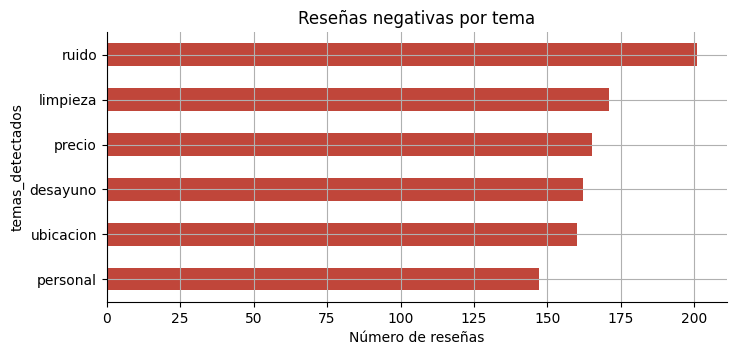

Reseñas negativas por tema: {'ruido': 201, 'limpieza': 171, 'precio': 165, 'desayuno': 162, 'ubicacion': 160, 'personal': 147}
Queja principal: ruido
✔ Mini-reto correcto


In [ ]:
# pista: explode() sobre temas_detectados de las negativas, value_counts()
quejas = resenas.loc[resenas["sentimiento"] == "negativo", "temas_detectados"].explode().value_counts()
queja_principal = quejas.index[0]

fig, ax = plt.subplots()
quejas.sort_values().plot.barh(ax=ax, color="#c0463a")
ax.set_title("Reseñas negativas por tema"); ax.set_xlabel("Número de reseñas")
plt.show()
assert quejas.is_monotonic_decreasing, "quejas debe estar ordenada de mayor a menor."
assert queja_principal in TEMAS, "queja_principal debe ser un tema del diccionario."
assert quejas.sum() >= 300, "Cuenta solo reseñas negativas, un tema por fila (usa explode)."
print("Reseñas negativas por tema:", quejas.to_dict())
print("Queja principal:", queja_principal)
print("✔ Mini-reto correcto")

In [ ]:
negativas = resenas[resenas["sentimiento"] == "negativo"]
positivas = resenas[resenas["sentimiento"] == "positivo"]
tabla_temas = pd.DataFrame({
    "negativas": negativas["temas_reales"].explode().value_counts(),
    "positivas": positivas["temas_reales"].explode().value_counts(),
}).sort_values("negativas", ascending=False)
print(len(negativas), "críticas y", len(positivas), "elogios")
print(tabla_temas)
print((tabla_temas / [len(negativas), len(positivas)] * 100).round(0))

478 críticas y 704 elogios
              negativas  positivas
temas_reales                      
limpieza            171        249
precio              165        243
desayuno            162        237
ubicacion           160        244
ruido               155        244
personal            147        218
              negativas  positivas
temas_reales                      
limpieza           36.0       35.0
precio             35.0       35.0
desayuno           34.0       34.0
ubicacion          33.0       35.0
ruido              32.0       35.0
personal           31.0       31.0


In [ ]:
citas = resenas[(resenas["sentimiento"] == "negativo") & resenas["temas"].str.contains("limpieza", na=False)]
print(len(citas), "críticas mencionan limpieza")
for _, fila in citas.head(3).iterrows():
    print(fila["id_resena"], "·", fila["texto"])

171 críticas mencionan limpieza
13 · Viajamos en familia. La limpieza deja mucho que desear...
17 · Pasamos una semana aquí. La habitación estaba sucia.
20 · Pasamos una semana aquí. Tardaron una hora en resolver un problema simple. Ruido constante por la noche. La habitación estaba sucia.


## Preguntas de reflexión
1. La exactitud es muy alta. ¿Por qué no debemos fiarnos tanto de ese número con reseñas **sintéticas** y repetitivas?
2. ¿Qué ventaja tiene un modelo que puedes explicar (pesos de palabras) frente a uno que no?
3. ¿Qué haría falta para manejar ironía ("¡Qué gran idea poner música a las 3 de la mañana!")?
4. Las reseñas pueden contener nombres o datos personales: ¿qué harías antes de guardarlas y analizarlas?

<details><summary>Ver respuestas (después de pensarlo)</summary>

1. Porque las reseñas sintéticas están hechas con **frases de plantilla** muy repetitivas: el modelo reconoce las plantillas y no la opinión, así que acierta un 99 %. Con reseñas reales (faltas, ironía, frases largas y variadas) la exactitud sería mucho menor, y no sabemos cuánto hasta probarlo con datos reales.
2. Se puede **explicar** al cliente por qué decide («sucia», «borde», «caro» empujan a negativo), **detectar errores** (por ejemplo, palabras sin sentido con mucho peso) y cumplir con el derecho a una explicación (RGPD). Un modelo que no se explica es una caja negra difícil de revisar y de defender.
3. Haría falta entender el **contexto y el orden**, no solo las palabras: modelos de lenguaje (como los *transformers*), datos etiquetados con ironía y, para el tono, quizás emojis o contexto de la conversación. Los bigramas ayudan con la negación pero no resuelven la ironía.
4. **Anonimizar** (quitar o sustituir nombres, correos, teléfonos), guardar solo lo necesario, restringir quién accede y tener una **base legal** y un plazo de conservación (RGPD). Es mejor anonimizar antes de guardar que después.

</details>

## Resumen: qué has aprendido
- Limpiar, tokenizar y quitar palabras vacías (sin quitar "no").
- Bolsa de palabras y TF-IDF convierten texto en números; se ajustan **solo con el entrenamiento**.
- Regresión logística y Naive Bayes clasifican bien y se pueden explicar; fallan con negaciones.
- Las palabras clave dan temas de forma transparente; los n-gramas muestran quejas concretas.